#  FoodLens – AI-Based Food Quality Assessment Using Deep Learning
**Model:** MobileNetV2 (transfer learning) ·
**Task:** classify fruit images as *fresh* or *rotten* (and which fruit)
**Dataset:** [Fruits fresh and rotten for classification](https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification) (Kaggle)



## 1. Setup

In [ ]:
import os, random, numpy as np, matplotlib.pyplot as plt, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices('GPU')
print("TensorFlow:", tf.__version__)
print("GPU:", gpus if gpus else "❌ NONE – switch to T4 GPU (Runtime → Change runtime type), otherwise training will be ~20x slower")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download dataset from Kaggle

In [ ]:
!pip install -q kagglehub
import kagglehub
path = kagglehub.dataset_download("sriramr/fruits-fresh-and-rotten-for-classification")
print("Dataset path:", path)

Using Colab cache for faster access to the 'fruits-fresh-and-rotten-for-classification' dataset.
Dataset path: /kaggle/input/fruits-fresh-and-rotten-for-classification


> If the download asks for a login, upload your `kaggle.json` (kaggle.com → Settings → *Create New Token*) and run instead:
> ```python
> from google.colab import files; files.upload()
> !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
> !kaggle datasets download -d sriramr/fruits-fresh-and-rotten-for-classification -p data --unzip
> path = "data"
> ```

In [ ]:
def find_dir(root, name):
    for dp, dn, _ in os.walk(root):
        if name in dn: return os.path.join(dp, name)

train_dir = find_dir(path, "train")
test_dir  = find_dir(path, "test")
print("train:", train_dir); print("test :", test_dir)

train: /kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/train
test : /kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/test


## 3. Explore the data

Train: {'freshapples': 1693, 'freshbanana': 1581, 'freshoranges': 1466, 'rottenapples': 2342, 'rottenbanana': 2224, 'rottenoranges': 1595} → 10901
Test : {'freshapples': 395, 'freshbanana': 381, 'freshoranges': 388, 'rottenapples': 601, 'rottenbanana': 530, 'rottenoranges': 403} → 2698


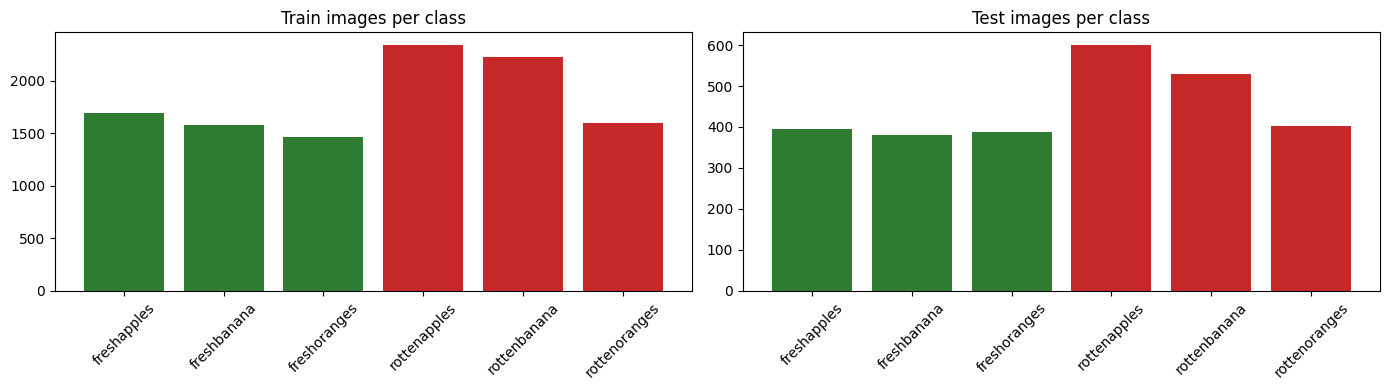

In [ ]:
def count_images(d):
    return {c: len(os.listdir(os.path.join(d, c))) for c in sorted(os.listdir(d))}

train_counts, test_counts = count_images(train_dir), count_images(test_dir)
print("Train:", train_counts, "→", sum(train_counts.values()))
print("Test :", test_counts,  "→", sum(test_counts.values()))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, (t, c) in zip(ax, [("Train", train_counts), ("Test", test_counts)]):
    a.bar(c.keys(), c.values(), color=["#2e7d32" if k.startswith("fresh") else "#c62828" for k in c])
    a.set_title(f"{t} images per class"); a.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

## 4. Data pipeline

Found 10901 files belonging to 6 classes.
Using 8721 files for training.
Found 10901 files belonging to 6 classes.
Using 2180 files for validation.
Found 2698 files belonging to 6 classes.
Classes: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']


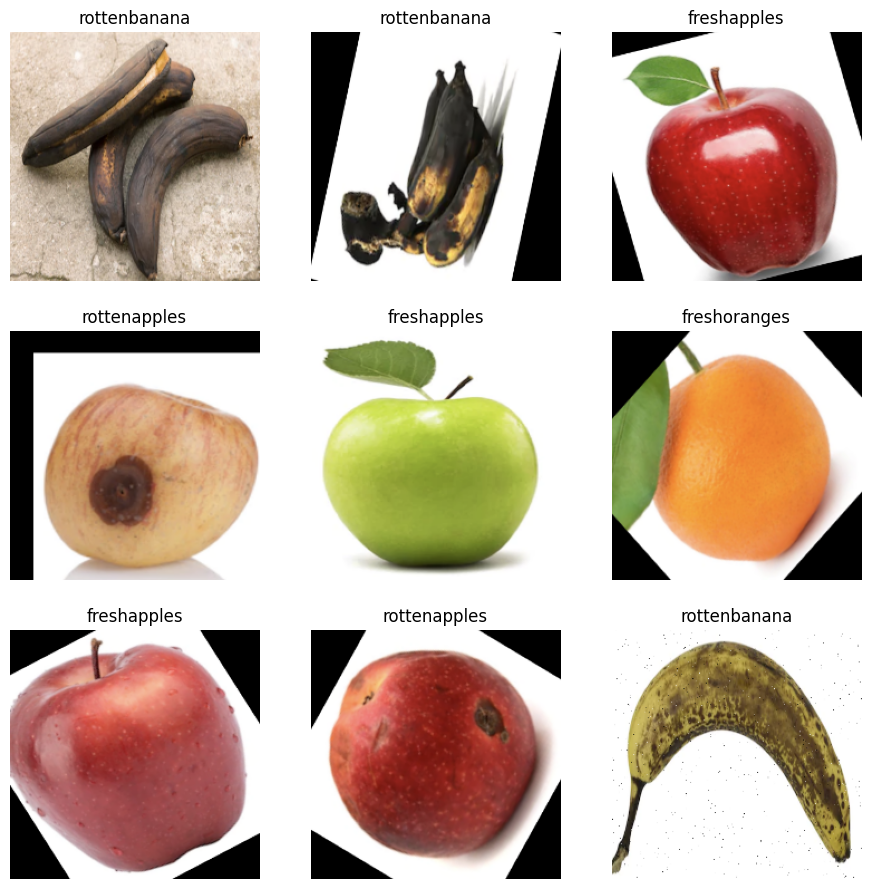

In [ ]:
IMG = (224, 224); BATCH = 32

train_ds = keras.utils.image_dataset_from_directory(train_dir, validation_split=0.2, subset="training",
            seed=SEED, image_size=IMG, batch_size=BATCH)
val_ds   = keras.utils.image_dataset_from_directory(train_dir, validation_split=0.2, subset="validation",
            seed=SEED, image_size=IMG, batch_size=BATCH)
test_ds  = keras.utils.image_dataset_from_directory(test_dir, image_size=IMG, batch_size=BATCH, shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)

plt.figure(figsize=(11, 11))
for imgs, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i+1); plt.imshow(imgs[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]]); plt.axis("off")
plt.show()

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE); val_ds = val_ds.prefetch(AUTOTUNE); test_ds = test_ds.prefetch(AUTOTUNE)

## 5. Build the model (MobileNetV2 + custom head)

In [ ]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augmentation")

base = keras.applications.MobileNetV2(input_shape=IMG + (3,), include_top=False, weights="imagenet")
base.trainable = False   # stage 1: feature extraction

inputs = keras.Input(shape=IMG + (3,), name="image")
x = augment(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)

model = keras.Model(inputs, outputs, name="FoodLens_MobileNetV2")
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "FoodLens_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 6. Stage 1 – Train the classification head (base frozen)

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=2, factor=0.3, verbose=1),
    keras.callbacks.ModelCheckpoint("foodlens_best.keras", monitor="val_accuracy", save_best_only=True),
]
h1 = model.fit(train_ds, validation_data=val_ds, epochs=8, callbacks=callbacks)

Epoch 1/8
273/273 ━━━━━━━━━━━━━━━━━━━━ 75s 225ms/step - accuracy: 0.8961 - loss: 0.3156 - val_accuracy: 0.9757 - val_loss: 0.0928 - learning_rate: 0.0010
Epoch 2/8
273/273 ━━━━━━━━━━━━━━━━━━━━ 45s 165ms/step - accuracy: 0.9705 - loss: 0.1002 - val_accuracy: 0.9812 - val_loss: 0.0669 - learning_rate: 0.0010
Epoch 3/8
273/273 ━━━━━━━━━━━━━━━━━━━━ 44s 162ms/step - accuracy: 0.9768 - loss: 0.0765 - val_accuracy: 0.9839 - val_loss: 0.0559 - learning_rate: 0.0010
Epoch 4/8
273/273 ━━━━━━━━━━━━━━━━━━━━ 43s 158ms/step - accuracy: 0.9786 - loss: 0.0640 - val_accuracy: 0.9885 - val_loss: 0.0438 - learning_rate: 0.0010
Epoch 5/8
273/273 ━━━━━━━━━━━━━━━━━━━━ 81s 156ms/step - accuracy: 0.9838 - loss: 0.0539 - val_accuracy: 0.9890 - val_loss: 0.0354 - learning_rate: 0.0010
Epoch 6/8
273/273 ━━━━━━━━━━━━━━━━━━━━ 43s 157ms/step - accuracy: 0.9866 - loss: 0.0441 - val_accuracy: 0.9885 - val_loss: 0.0400 - learning_rate: 0.0010
Epoch 7/8
273/273 ━━━━━━━━━━━━━━━━━━━━ 82s 157ms/step - accuracy: 0.9877 - l

## 7. Stage 2 – Fine-tune the top layers of MobileNetV2

In [ ]:
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False          # keep early layers frozen, tune last 30

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=6, callbacks=callbacks)

Epoch 1/6
273/273 ━━━━━━━━━━━━━━━━━━━━ 57s 169ms/step - accuracy: 0.8892 - loss: 0.3393 - val_accuracy: 0.9858 - val_loss: 0.0412 - learning_rate: 1.0000e-05
Epoch 2/6
272/273 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.9722 - loss: 0.0928
Epoch 2: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
273/273 ━━━━━━━━━━━━━━━━━━━━ 83s 174ms/step - accuracy: 0.9728 - loss: 0.0829 - val_accuracy: 0.9862 - val_loss: 0.0415 - learning_rate: 1.0000e-05
Epoch 3/6
273/273 ━━━━━━━━━━━━━━━━━━━━ 79s 164ms/step - accuracy: 0.9806 - loss: 0.0622 - val_accuracy: 0.9885 - val_loss: 0.0302 - learning_rate: 3.0000e-06


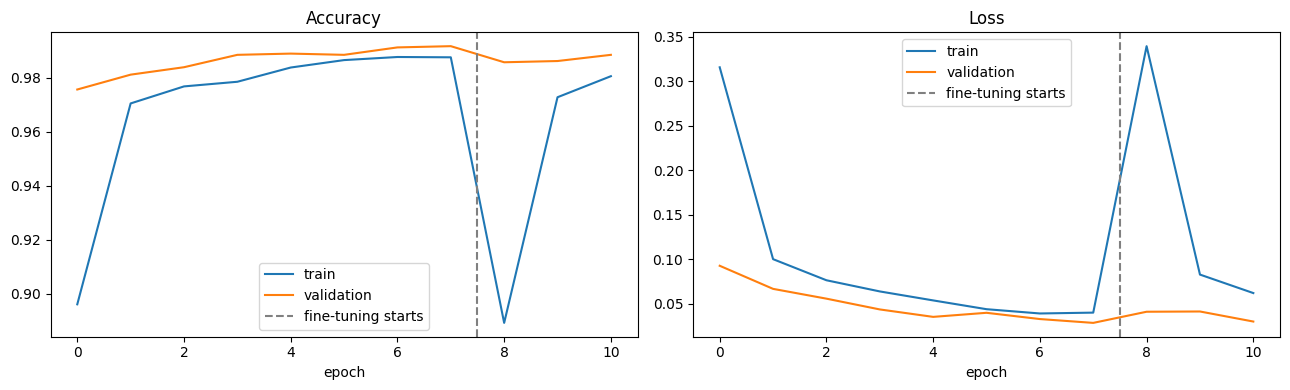

In [ ]:
acc  = h1.history['accuracy']     + h2.history['accuracy']
val  = h1.history['val_accuracy'] + h2.history['val_accuracy']
loss = h1.history['loss']         + h2.history['loss']
vl   = h1.history['val_loss']     + h2.history['val_loss']
split = len(h1.history['accuracy']) - 0.5

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (tr, va, t) in zip(ax, [(acc, val, "Accuracy"), (loss, vl, "Loss")]):
    a.plot(tr, label="train"); a.plot(va, label="validation")
    a.axvline(split, color="gray", ls="--", label="fine-tuning starts")
    a.set_title(t); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

## 8. Evaluate on the test set

85/85 ━━━━━━━━━━━━━━━━━━━━ 11s 124ms/step - accuracy: 0.9807 - loss: 0.0488

Test accuracy: 98.07%   Test loss: 0.0488
85/85 ━━━━━━━━━━━━━━━━━━━━ 14s 131ms/step
               precision    recall  f1-score   support

  freshapples     0.9379    0.9949    0.9656       395
  freshbanana     1.0000    1.0000    1.0000       381
 freshoranges     0.9484    0.9948    0.9711       388
 rottenapples     0.9914    0.9601    0.9755       601
 rottenbanana     1.0000    1.0000    1.0000       530
rottenoranges     1.0000    0.9404    0.9693       403

     accuracy                         0.9807      2698
    macro avg     0.9796    0.9817    0.9802      2698
 weighted avg     0.9816    0.9807    0.9808      2698



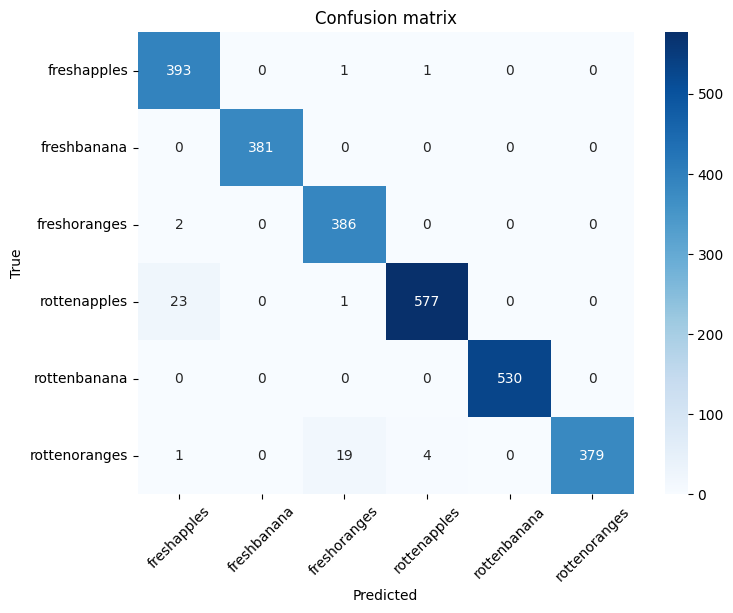

Fresh-vs-Rotten accuracy: 98.33%
Misclassified images: 52


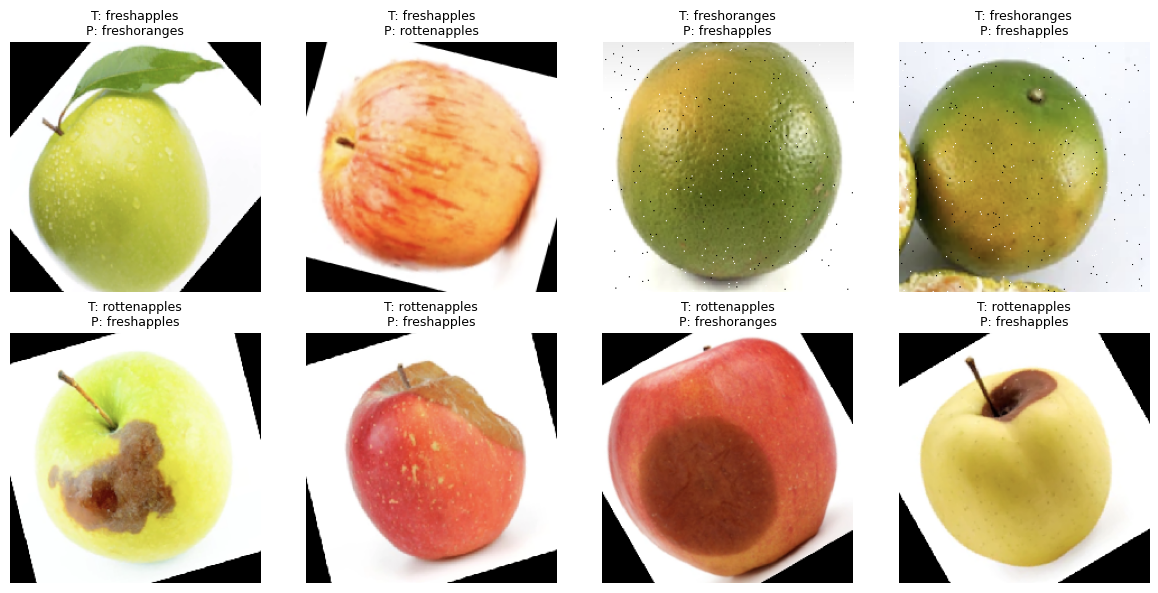

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import glob

test_loss, test_acc = model.evaluate(test_ds)
print(f"\nTest accuracy: {test_acc*100:.2f}%   Test loss: {test_loss:.4f}")

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix"); plt.xticks(rotation=45); plt.show()

# Quality-level metric: fresh vs rotten, ignoring which fruit
is_fresh = np.array([n.startswith("fresh") for n in class_names])
fr_acc = np.mean(is_fresh[y_true] == is_fresh[y_pred])
print(f"Fresh-vs-Rotten accuracy: {fr_acc*100:.2f}%")

# Misclassified examples
wrong = np.where(y_true != y_pred)[0]
print("Misclassified images:", len(wrong))
if len(wrong):
    # Reconstruct file paths sorted alphabetically (since test_ds had shuffle=False)
    paths = sorted(glob.glob(os.path.join(test_dir, "*", "*")))
    plt.figure(figsize=(12, 6))
    for i, idx in enumerate(wrong[:8]):
        plt.subplot(2, 4, i+1); plt.imshow(keras.utils.load_img(paths[idx], target_size=IMG))
        plt.title(f"T: {class_names[y_true[idx]]}\nP: {class_names[y_pred[idx]]}", fontsize=9); plt.axis("off")
    plt.tight_layout(); plt.show()

## 9. Explainability – Grad-CAM (where is the model looking?)

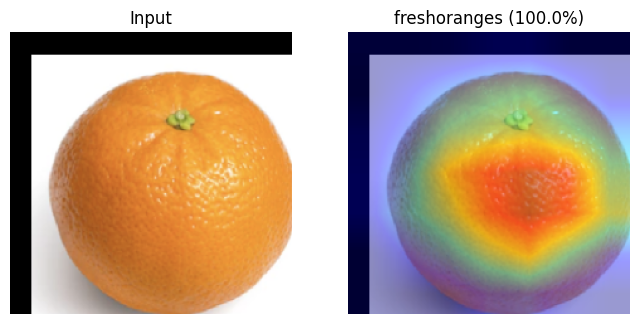

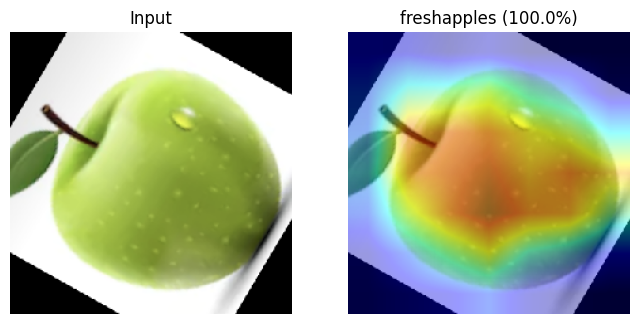

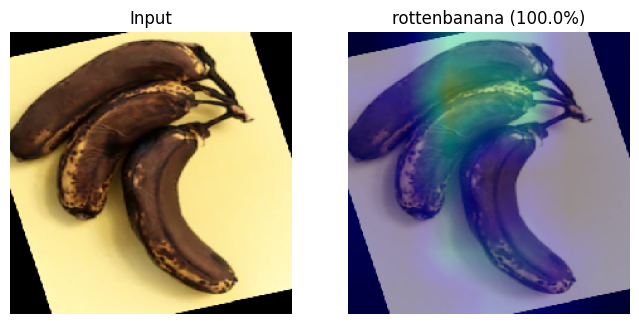

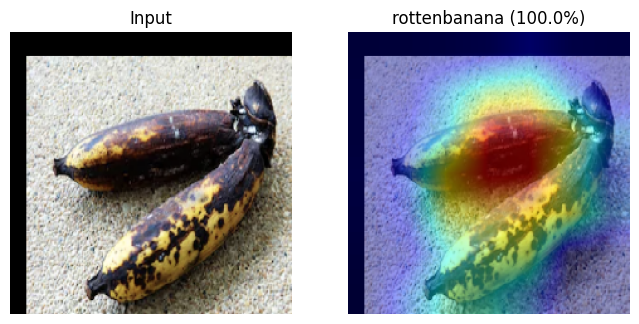

In [ ]:
import cv2
import glob

head_gap  = model.get_layer("gap")
head_dense = model.get_layer("predictions")

def grad_cam(img_array, class_idx=None):
    x = tf.convert_to_tensor(img_array[None, ...], dtype=tf.float32)
    x = keras.applications.mobilenet_v2.preprocess_input(x)
    with tf.GradientTape() as tape:
        conv = base(x, training=False)
        tape.watch(conv)
        preds = head_dense(head_gap(conv))
        if class_idx is None: class_idx = int(tf.argmax(preds[0]))
        score = preds[:, class_idx]
    grads = tape.gradient(score, conv)
    weights = tf.reduce_mean(grads, axis=(1, 2))[0]
    cam = tf.reduce_sum(conv[0] * weights, axis=-1).numpy()
    cam = np.maximum(cam, 0); cam /= (cam.max() + 1e-8)
    return cv2.resize(cam, IMG), int(class_idx), preds.numpy()[0]

def show_gradcam(img_path):
    img = keras.utils.img_to_array(keras.utils.load_img(img_path, target_size=IMG))
    cam, k, probs = grad_cam(img)
    heat = cv2.applyColorMap(np.uint8(255*cam), cv2.COLORMAP_JET)[..., ::-1]
    overlay = np.uint8(0.6*img + 0.4*heat)
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(img.astype("uint8")); ax[0].set_title("Input"); ax[0].axis("off")
    ax[1].imshow(overlay); ax[1].set_title(f"{class_names[k]} ({probs[k]*100:.1f}%)"); ax[1].axis("off")
    plt.show()

# Reconstruct the exact list of file paths used in order
test_paths = sorted(glob.glob(os.path.join(test_dir, "*", "*")))
for p in random.sample(test_paths, 4):
    show_gradcam(p)

## 10.  FoodLens – check your own food image

Saving Screenshot 2026-11-14 121055.png to Screenshot 2026-11-14 121055.png


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


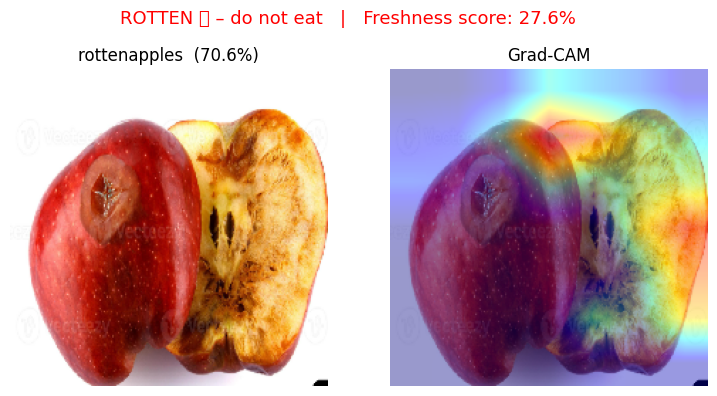

In [ ]:
from google.colab import files

def foodlens_predict(img_path):
    img = keras.utils.img_to_array(keras.utils.load_img(img_path, target_size=IMG))
    probs = model.predict(img[None, ...], verbose=0)[0]
    k = int(np.argmax(probs)); label = class_names[k]
    fresh_score = probs[is_fresh].sum() * 100          # total probability of the 'fresh' classes
    verdict = "FRESH ✅ – safe to eat" if fresh_score >= 50 else "ROTTEN ❌ – do not eat"
    cam, _, _ = grad_cam(img, k)
    heat = cv2.applyColorMap(np.uint8(255*cam), cv2.COLORMAP_JET)[..., ::-1]

    fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
    ax[0].imshow(img.astype("uint8")); ax[0].axis("off")
    ax[0].set_title(f"{label}  ({probs[k]*100:.1f}%)")
    ax[1].imshow(np.uint8(0.6*img + 0.4*heat)); ax[1].axis("off"); ax[1].set_title("Grad-CAM")
    fig.suptitle(f"{verdict}   |   Freshness score: {fresh_score:.1f}%", fontsize=13,
                 color="green" if fresh_score >= 50 else "red")
    plt.show()

uploaded = files.upload()
for fn in uploaded:
    foodlens_predict(fn)

## 11. Save and export

In [ ]:
model.save("foodlens_mobilenetv2.keras")

# TensorFlow Lite version for mobile apps
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()
open("foodlens_mobilenetv2.tflite", "wb").write(tflite_model)
open("labels.txt", "w").write("\n".join(class_names))
print("Keras model :", round(os.path.getsize("foodlens_mobilenetv2.keras")/1e6, 1), "MB")
print("TFLite model:", round(len(tflite_model)/1e6, 1), "MB")

files.download("foodlens_mobilenetv2.keras")
files.download("foodlens_mobilenetv2.tflite")
files.download("labels.txt")

Saved artifact at '/tmp/tmp9szlmemc'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  136724112579216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136724020116368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136724020104080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136724112576528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136724023708560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136724020114256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136724021992464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136724021993232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136724020110416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136724020109456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136724021996112: Tens

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##  Report notes
- **Problem:** manual food inspection is slow, subjective and error-prone → FoodLens automates freshness assessment from a photo.
- **Dataset:** Kaggle fruits fresh/rotten (apples, bananas, oranges; 6 classes).
- **Method:** MobileNetV2 (ImageNet weights) + data augmentation → train head → fine-tune last 30 layers.
- **Metrics:** accuracy, precision/recall/F1, confusion matrix, fresh-vs-rotten accuracy, misclassification review.
- **Explainability:** Grad-CAM heatmaps show the model focuses on the fruit's skin/spots.
- **Deployment:** exported to TensorFlow Lite for mobile.
- **Limitations:** only 3 fruits, clean backgrounds; may not generalise to other foods or real-world lighting.
- **Future work:** more food types, real-world images, regression-style freshness score, mobile app.